# 01 - Exploratory Data Analysis
**Kasus:** Klasifikasi tingkat kerusakan bangunan (damage_grade 1–5) pasca gempa Gorkha, Nepal 2015  
**Metrik evaluasi:** Macro F1-Score  
**Tujuan EDA:** memahami struktur, kualitas, dan pola data sebagai dasar keputusan preprocessing dan modeling.

## Daftar isi
0. Setup & kamus data  
1. Struktur data  
2. Kualitas data  
3. Analisis target  
4. Pengelompokan tipe kolom  
5. Univariat numerik  
6. Univariat kategorik & biner  
7. Bivariat (fitur vs target)  
8. Multivariat  
9. Perbandingan train vs test  
10. Cek leakage  
11. Kesimpulan & keputusan preprocessing

In [2]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

# Pengaturan tampilan
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)              # semua kolom ditampilkan
pd.set_option("display.float_format", "{:.3f}".format)  # desimal dibatasi 3 digit
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Path data
DATA_DIR = "../data/"  

print("Library siap | pandas", pd.__version__)

Library siap | pandas 3.0.6


In [3]:
# Membaca kamus data
pd.set_option("display.max_colwidth", None)   
metadata = pd.read_csv(DATA_DIR + "metadata.csv")
metadata

,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building from the survey,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before the earthquake,Number
5,age_building,Age of the building (in years),Number
6,plinth_area_sq_ft,Plinth area of the building (in square feet),Number
7,height_ft_pre_eq,Height of the building before the earthquake (in feet),Number
8,land_surface_condition,Surface condition of the land in which the building is built,Categorical
9,foundation_type,Type of foundation used in the building,Categorical


In [4]:
# Jumlah kolom per tipe
metadata["Type"].value_counts()

Type
Boolean        11
Categorical     8
Text            4
Number          4
Name: count, dtype: int64

**Insight:**
- Total 27 kolom: 1 ID (`building_id`), 25 fitur, 1 target (`damage_grade`).
- 3 kolom geografis (`district_id`, `vdcmun_id`, `ward_id`) bertipe kode wilayah berjenjang, bukan besaran numerik.
- 4 kolom numerik: jumlah lantai, umur, luas plinth, tinggi bangunan.
- 7 kolom kategorik terkait konstruksi (fondasi, atap, lantai, posisi, denah, kondisi tanah).
- 11 kolom biner `has_superstructure_*` penanda material struktur utama.
- Target bersifat ordinal (1–5).
- Seluruh fitur merupakan kondisi sebelum gempa, sehingga indikasi leakage tidak ditemukan dari kamus data.

In [5]:
## 1. Struktur Data
# Membaca data train dan test
train = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")

print("Train:", train.shape)
print("Test :", test.shape)

Train: (533465, 17)
Test : (228629, 16)


In [6]:
train.head()

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


**Temuan struktur awal:**
- Train berisi 533.465 baris × 17 kolom, test berisi 228.629 baris × 16 kolom.
- Jumlah kolom tidak sesuai metadata (27): 11 kolom biner `has_superstructure_*` telah digabung menjadi satu kolom kategorik `superstructure`.
- Target `damage_grade` tersimpan sebagai teks ("Grade 1"–"Grade 5") sehingga perlu dikonversi menjadi angka 1–5.

In [7]:
# Tipe data dan jumlah non-null tiap kolom
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

In [8]:
# Kolom yang hanya ada di train
print("Hanya di train:", set(train.columns) - set(test.columns))
print("Hanya di test :", set(test.columns) - set(train.columns))

Hanya di train: {'damage_grade'}
Hanya di test : set()


In [9]:
# Keunikan building_id
print("ID unik train:", train["building_id"].is_unique)
print("ID unik test :", test["building_id"].is_unique)
print("ID train yang muncul di test:", train["building_id"].isin(test["building_id"]).sum())

ID unik train: True
ID unik test : True
ID train yang muncul di test: 0


**Insight struktur:**
- Tidak ditemukan missing value eksplisit pada seluruh kolom train.
- Kolom fitur train dan test identik, perbedaan hanya pada target `damage_grade`.
- `building_id` unik dan tidak ada irisan antara train dan test.
- 8 kolom bertipe integer (ID, 3 kode wilayah, 4 numerik) dan 9 kolom bertipe teks (7 kategorik, `superstructure`, target).

In [10]:
## 2. Kualitas Data
# Missing value pada test
test.isna().sum().sum()

np.int64(0)

In [11]:
# Baris duplikat tanpa memperhitungkan building_id
fitur = train.columns.drop(["building_id", "damage_grade"])
dup_fitur = train.duplicated(subset=fitur).sum()
dup_konflik = train[train.duplicated(subset=fitur, keep=False)].groupby(list(fitur))["damage_grade"].nunique().gt(1).sum()

print("Baris dengan fitur identik:", dup_fitur)
print("Kelompok fitur identik tapi grade berbeda:", dup_konflik)

Baris dengan fitur identik: 34062
Kelompok fitur identik tapi grade berbeda: 10695


In [12]:
# Nilai unik tiap kolom teks
kolom_teks = train.select_dtypes(include="str").columns

for col in kolom_teks:
    print(f"\n{col} ({train[col].nunique()} kategori)")
    print(train[col].value_counts())


land_surface_condition (3 kategori)
land_surface_condition
Flat              442089
Moderate slope     73944
Steep slope        17432
Name: count, dtype: int64

foundation_type (5 kategori)
foundation_type
Mud mortar-Stone/Brick    440105
Bamboo/Timber              40167
Cement-Stone/Brick         27562
RC                         22445
Other                       3186
Name: count, dtype: int64

roof_type (3 kategori)
roof_type
Bamboo/Timber-Light roof    352493
Bamboo/Timber-Heavy roof    149836
RCC/RB/RBC                   31136
Name: count, dtype: int64

ground_floor_type (5 kategori)
ground_floor_type
Mud            432806
RC              51146
Brick/Stone     46264
Timber           2507
Other             742
Name: count, dtype: int64

other_floor_type (4 kategori)
other_floor_type
TImber/Bamboo-Mud    340906
Timber-Planck         86637
Not applicable        83103
RCC/RB/RBC            22819
Name: count, dtype: int64

position (4 kategori)
position
Not attached       423151
Attache

In [13]:
# Statistik deskriptif kolom numerik
num_cols = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
train[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
count_floors_pre_eq,533465.000,2.088,0.655,1.000,1.000,2.000,2.000,2.000,4.000,9.000
age_building,533465.000,24.337,64.999,0.000,1.000,9.000,16.000,27.000,90.000,999.000
plinth_area_sq_ft,533465.000,406.523,226.610,70.000,120.000,280.000,358.000,470.000,1222.000,5000.000
height_ft_pre_eq,533465.000,16.048,5.491,6.000,6.000,12.000,16.000,18.000,32.000,99.000


In [14]:
for col in ["ground_floor_type", "other_floor_type", "position", "plan_configuration", "damage_grade", "superstructure"]:
    print(f"\n{col} ({train[col].nunique()} kategori)")
    print(train[col].value_counts())


ground_floor_type (5 kategori)
ground_floor_type
Mud            432806
RC              51146
Brick/Stone     46264
Timber           2507
Other             742
Name: count, dtype: int64

other_floor_type (4 kategori)
other_floor_type
TImber/Bamboo-Mud    340906
Timber-Planck         86637
Not applicable        83103
RCC/RB/RBC            22819
Name: count, dtype: int64

position (4 kategori)
position
Not attached       423151
Attached-1 side     90493
Attached-2 side     18943
Attached-3 side       878
Name: count, dtype: int64

plan_configuration (10 kategori)
plan_configuration
Rectangular                        511999
Square                              12229
L-shape                              7009
T-shape                               668
Multi-projected                       636
Others                                387
U-shape                               313
E-shape                                99
Building with Central Courtyard        64
H-shape                            

In [15]:
# Jumlah nilai ekstrem pada kolom numerik
print("age_building >= 200 :", (train["age_building"] >= 200).sum())
print("age_building == 999 :", (train["age_building"] == 999).sum())
print("age_building == 0   :", (train["age_building"] == 0).sum())
print("height_ft == 99     :", (train["height_ft_pre_eq"] == 99).sum())
print("floors >= 6         :", (train["count_floors_pre_eq"] >= 6).sum())

# Nilai umur terbesar yang muncul
train["age_building"].value_counts().sort_index().tail(15)

age_building >= 200 : 2376
age_building == 999 : 2198
age_building == 0   : 3349
height_ft == 99     : 212
floors >= 6         : 307


age_building
172       2
174       3
175       2
176       1
177       1
178       2
180      13
185       1
187       1
190       5
195       2
196       2
199       1
200     178
999    2198
Name: count, dtype: int64

In [16]:
# Distribusi grade untuk umur 999 dibanding lainnya (dalam persen)
pd.crosstab(
    train["age_building"] == 999,
    train["damage_grade"],
    normalize="index"
).round(3) * 100

damage_grade,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
age_building,,,,,
False,10.300,11.400,17.900,24.100,36.200
True,11.900,11.400,19.700,21.600,35.300


In [17]:
# Jumlah lantai pada bangunan dengan tinggi 99 ft
train.loc[train["height_ft_pre_eq"] == 99, "count_floors_pre_eq"].value_counts().sort_index()

count_floors_pre_eq
1      2
2     45
3    165
Name: count, dtype: int64

**Keputusan penanganan nilai ekstrem:**
- Distribusi grade pada `age_building` = 999 hampir identik dengan bangunan lain, sehingga nilai tersebut diperlakukan sebagai missing (NaN) dan diimputasi median di dalam pipeline.
- Seluruh bangunan dengan `height_ft_pre_eq` = 99 hanya memiliki 1–3 lantai, sehingga nilai 99 dinilai tidak realistis dan diperlakukan sebagai missing (NaN) untuk diimputasi di dalam pipeline.
- Nilai ekstrem lain (`plinth_area_sq_ft` hingga 5.000, lantai hingga 9) dipertahankan karena masih masuk akal.

In [18]:
# Nilai unik kolom kategorik sisanya
for col in ["ground_floor_type", "other_floor_type", "position", "plan_configuration", "superstructure"]:
    print(f"\n{col} ({train[col].nunique()} kategori)")
    print(train[col].value_counts())


ground_floor_type (5 kategori)
ground_floor_type
Mud            432806
RC              51146
Brick/Stone     46264
Timber           2507
Other             742
Name: count, dtype: int64

other_floor_type (4 kategori)
other_floor_type
TImber/Bamboo-Mud    340906
Timber-Planck         86637
Not applicable        83103
RCC/RB/RBC            22819
Name: count, dtype: int64

position (4 kategori)
position
Not attached       423151
Attached-1 side     90493
Attached-2 side     18943
Attached-3 side       878
Name: count, dtype: int64

plan_configuration (10 kategori)
plan_configuration
Rectangular                        511999
Square                              12229
L-shape                              7009
T-shape                               668
Multi-projected                       636
Others                                387
U-shape                               313
E-shape                                99
Building with Central Courtyard        64
H-shape                            

In [19]:
## 3. Analisis Target
# Konversi target dari teks "Grade X" menjadi angka X
train["damage_grade"] = train["damage_grade"].str.replace("Grade ", "").astype(int)
train["damage_grade"].value_counts().sort_index()

damage_grade
1     55170
2     61080
3     95488
4    128691
5    193036
Name: count, dtype: int64

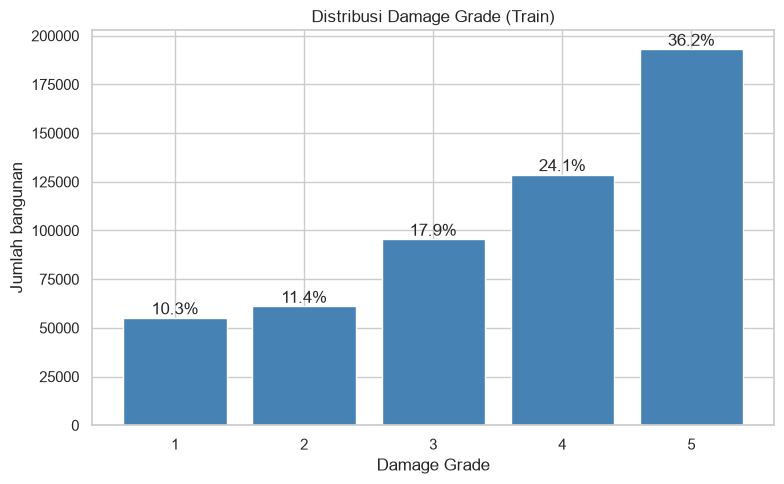

In [20]:
# Distribusi target
jumlah = train["damage_grade"].value_counts().sort_index()
persen = (jumlah / len(train) * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(jumlah.index.astype(str), jumlah.values, color="steelblue")
for bar, p in zip(bars, persen.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{p}%", ha="center", va="bottom")

ax.set_title("Distribusi Damage Grade (Train)")
ax.set_xlabel("Damage Grade")
ax.set_ylabel("Jumlah bangunan")
plt.tight_layout()
plt.savefig("../reports/figures/target_distribution.png", dpi=150)   # grafik disimpan untuk README
plt.show()

In [21]:
# Rasio kelas terbesar terhadap kelas terkecil
print("Rasio mayoritas/minoritas:", round(jumlah.max() / jumlah.min(), 2))
print("Akurasi jika selalu menebak grade 5:", round(jumlah.max() / len(train) * 100, 1), "%")

Rasio mayoritas/minoritas: 3.5
Akurasi jika selalu menebak grade 5: 36.2 %


**Insight target:**
- Jumlah bangunan meningkat seiring tingkat kerusakan: Grade 1 (10,3%), Grade 2 (11,4%), Grade 3 (17,9%), Grade 4 (24,1%), Grade 5 (36,2%).
- Rasio kelas mayoritas terhadap minoritas sebesar 3,5 sehingga data tergolong imbalanced sedang.
- Model yang selalu menebak Grade 5 menghasilkan akurasi 36,2%, sehingga akurasi tidak representatif dan Macro F1 digunakan sebagai metrik.
- Konsekuensi untuk modeling: validasi menggunakan StratifiedKFold serta penanganan imbalance (class weight atau penyesuaian threshold).

**Insight kategorik:**
- Seluruh kolom kategorik memiliki 3–5 kategori dengan satu kategori dominan (>80% pada `land_surface_condition`, `foundation_type`, `ground_floor_type`).
- Salah ketik "TImber" pada `other_floor_type` konsisten sehingga tidak memerlukan perbaikan.
- Kategori langka (`Other`, `Attached-3 side`) dipertahankan dan ditangani dengan `handle_unknown="ignore"` pada OneHotEncoder.

In [22]:
# Kategori plan_configuration
train["plan_configuration"].value_counts()

plan_configuration
Rectangular                        511999
Square                              12229
L-shape                              7009
T-shape                               668
Multi-projected                       636
Others                                387
U-shape                               313
E-shape                                99
Building with Central Courtyard        64
H-shape                                61
Name: count, dtype: int64

In [23]:
# Kategori superstructure dan pengecekan multi-material
print(train["superstructure"].value_counts())
print("\nBaris dengan lebih dari satu material:", train["superstructure"].str.contains(",|\\|").sum())

superstructure
has_superstructure_mud_mortar_stone       415327
has_superstructure_cement_mortar_brick     33289
has_superstructure_timber                  25407
has_superstructure_adobe_mud               22574
has_superstructure_rc_non_engineered        9051
has_superstructure_stone_flag               6994
has_superstructure_mud_mortar_brick         6746
has_superstructure_rc_engineered            5475
has_superstructure_cement_mortar_stone      4946
has_superstructure_bamboo                   2788
has_superstructure_other                     868
Name: count, dtype: int64

Baris dengan lebih dari satu material: 0


In [24]:
# Jumlah lantai pada kategori "Not applicable"
pd.crosstab(train["other_floor_type"] == "Not applicable", train["count_floors_pre_eq"])

count_floors_pre_eq,1,2,3,4,5,6,7,8,9
other_floor_type,,,,,,,,,
False,323,327420,116915,4318,1079,235,52,9,11
True,82854,246,3,0,0,0,0,0,0


**Insight kategorik lanjutan:**
- `plan_configuration` didominasi Rectangular (96%) dengan beberapa kategori sangat langka (<100 bangunan). Kategori langka akan digabung menggunakan parameter `min_frequency` pada OneHotEncoder.
- `superstructure` berisi tepat satu material per baris (11 kategori) sehingga diperlakukan sebagai satu kolom kategorik. Material mud mortar-stone mendominasi (78%).
- Kategori "Not applicable" pada `other_floor_type` 99,7% berasal dari bangunan 1 lantai, sehingga merupakan kategori bermakna ("tidak memiliki lantai lain") dan bukan missing value.

In [25]:
## 4. Pengelompokan Tipe Kolom
# Pengelompokan kolom berdasarkan hasil EDA
ID_COL = "building_id"
TARGET = "damage_grade"
GEO_COLS = ["district_id", "vdcmun_id", "ward_id"]
NUM_COLS = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
CAT_COLS = ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
            "other_floor_type", "position", "plan_configuration", "superstructure"]

total = 1 + 1 + len(GEO_COLS) + len(NUM_COLS) + len(CAT_COLS)
print(f"Geo: {len(GEO_COLS)} | Numerik: {len(NUM_COLS)} | Kategorik: {len(CAT_COLS)}")
print("Total kolom tercakup:", total, "| Kolom train:", train.shape[1])

Geo: 3 | Numerik: 4 | Kategorik: 8
Total kolom tercakup: 17 | Kolom train: 17


In [26]:
# Jumlah kategori kolom geografis dan kategori test yang tidak ada di train
for col in GEO_COLS:
    unseen = (~test[col].isin(train[col])).sum()
    print(f"{col}: train {train[col].nunique()} | test {test[col].nunique()} | baris test dengan kode baru: {unseen}")

district_id: train 11 | test 11 | baris test dengan kode baru: 0
vdcmun_id: train 110 | test 110 | baris test dengan kode baru: 0
ward_id: train 945 | test 945 | baris test dengan kode baru: 0


In [27]:
## 5. Univariat Numerik
# Salinan data dengan kode ekstrem diubah menjadi NaN (hanya untuk visualisasi)
eda = train.copy()
eda["age_building"] = eda["age_building"].replace(999, np.nan)
eda["height_ft_pre_eq"] = eda["height_ft_pre_eq"].replace(99, np.nan)
eda[NUM_COLS].isna().sum()

count_floors_pre_eq       0
age_building           2198
plinth_area_sq_ft         0
height_ft_pre_eq        212
dtype: int64

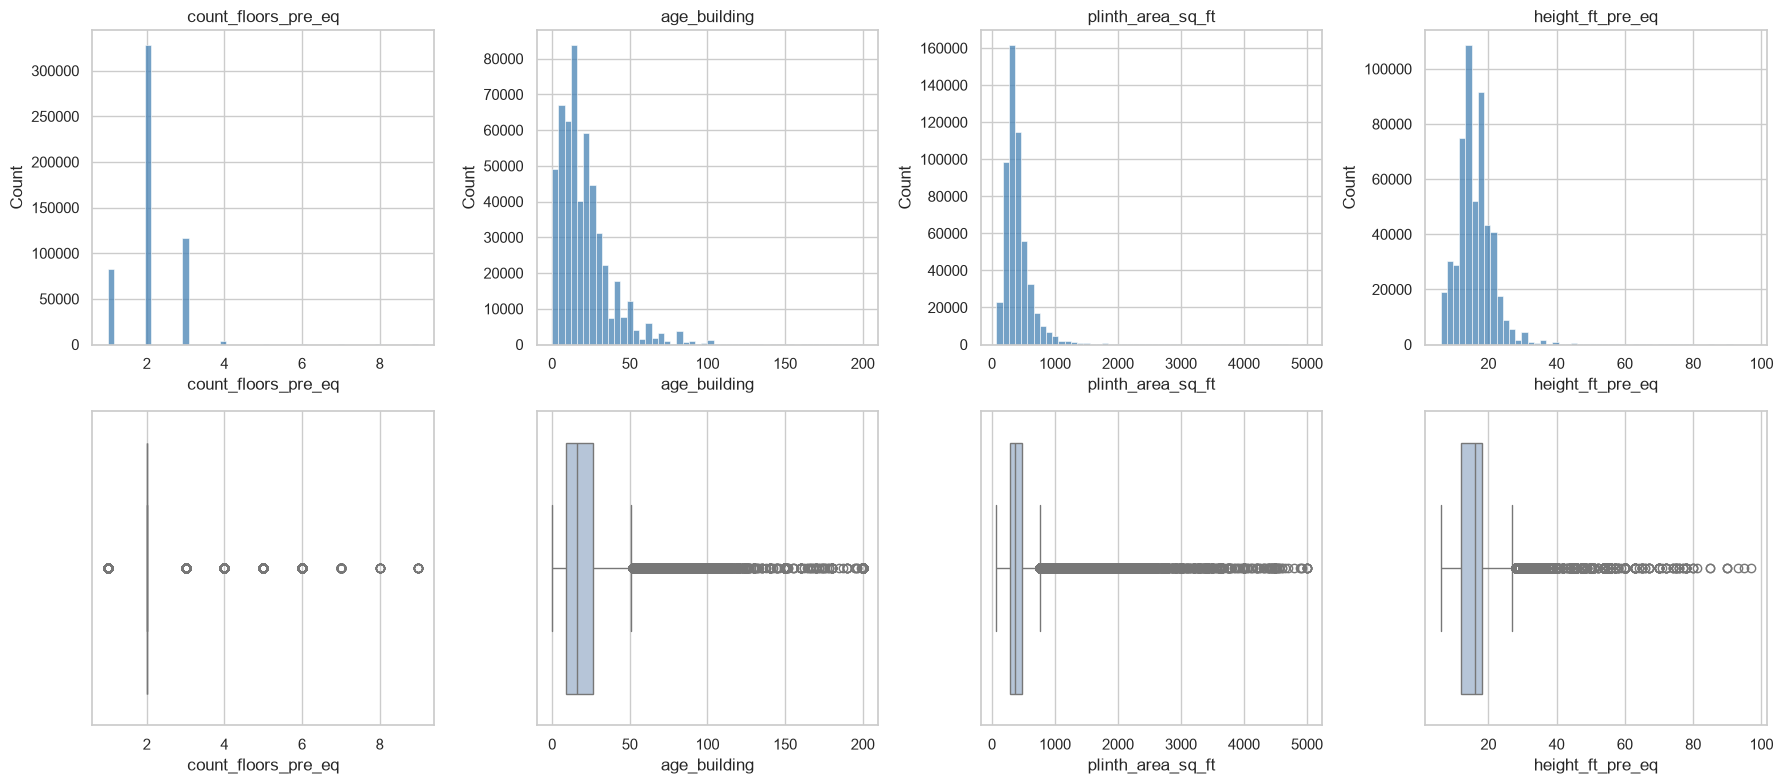

In [28]:
# Histogram dan boxplot kolom numerik
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, col in enumerate(NUM_COLS):
    sns.histplot(eda[col].dropna(), bins=50, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(col)
    sns.boxplot(x=eda[col].dropna(), ax=axes[1, i], color="lightsteelblue")

plt.tight_layout()
plt.savefig("../reports/figures/univariat_numerik.png", dpi=150)
plt.show()

In [29]:
# Kemencengan distribusi (|skew| > 1 dianggap sangat menceng)
eda[NUM_COLS].skew().round(2)

count_floors_pre_eq   0.430
age_building          2.190
plinth_area_sq_ft     3.870
height_ft_pre_eq      1.310
dtype: float64

**Insight univariat numerik:**
- `count_floors_pre_eq` bersifat diskrit dan didominasi 2 lantai; boxplot tidak representatif karena Q1 = Q3.
- `age_building` (skew 2,19) dan `height_ft_pre_eq` (skew 1,31) menceng kanan serta menunjukkan heaping pada angka bulat, mengindikasikan nilai hasil perkiraan.
- `plinth_area_sq_ft` paling menceng (skew 3,87) dengan ekor hingga 5.000 sq ft.
- Outlier tidak dihapus karena merepresentasikan bangunan nyata dan juga terdapat pada test.
- Rencana transformasi untuk model linear: `log1p` pada `plinth_area_sq_ft` dan `age_building`, diikuti StandardScaler. Model berbasis pohon tidak memerlukan transformasi.

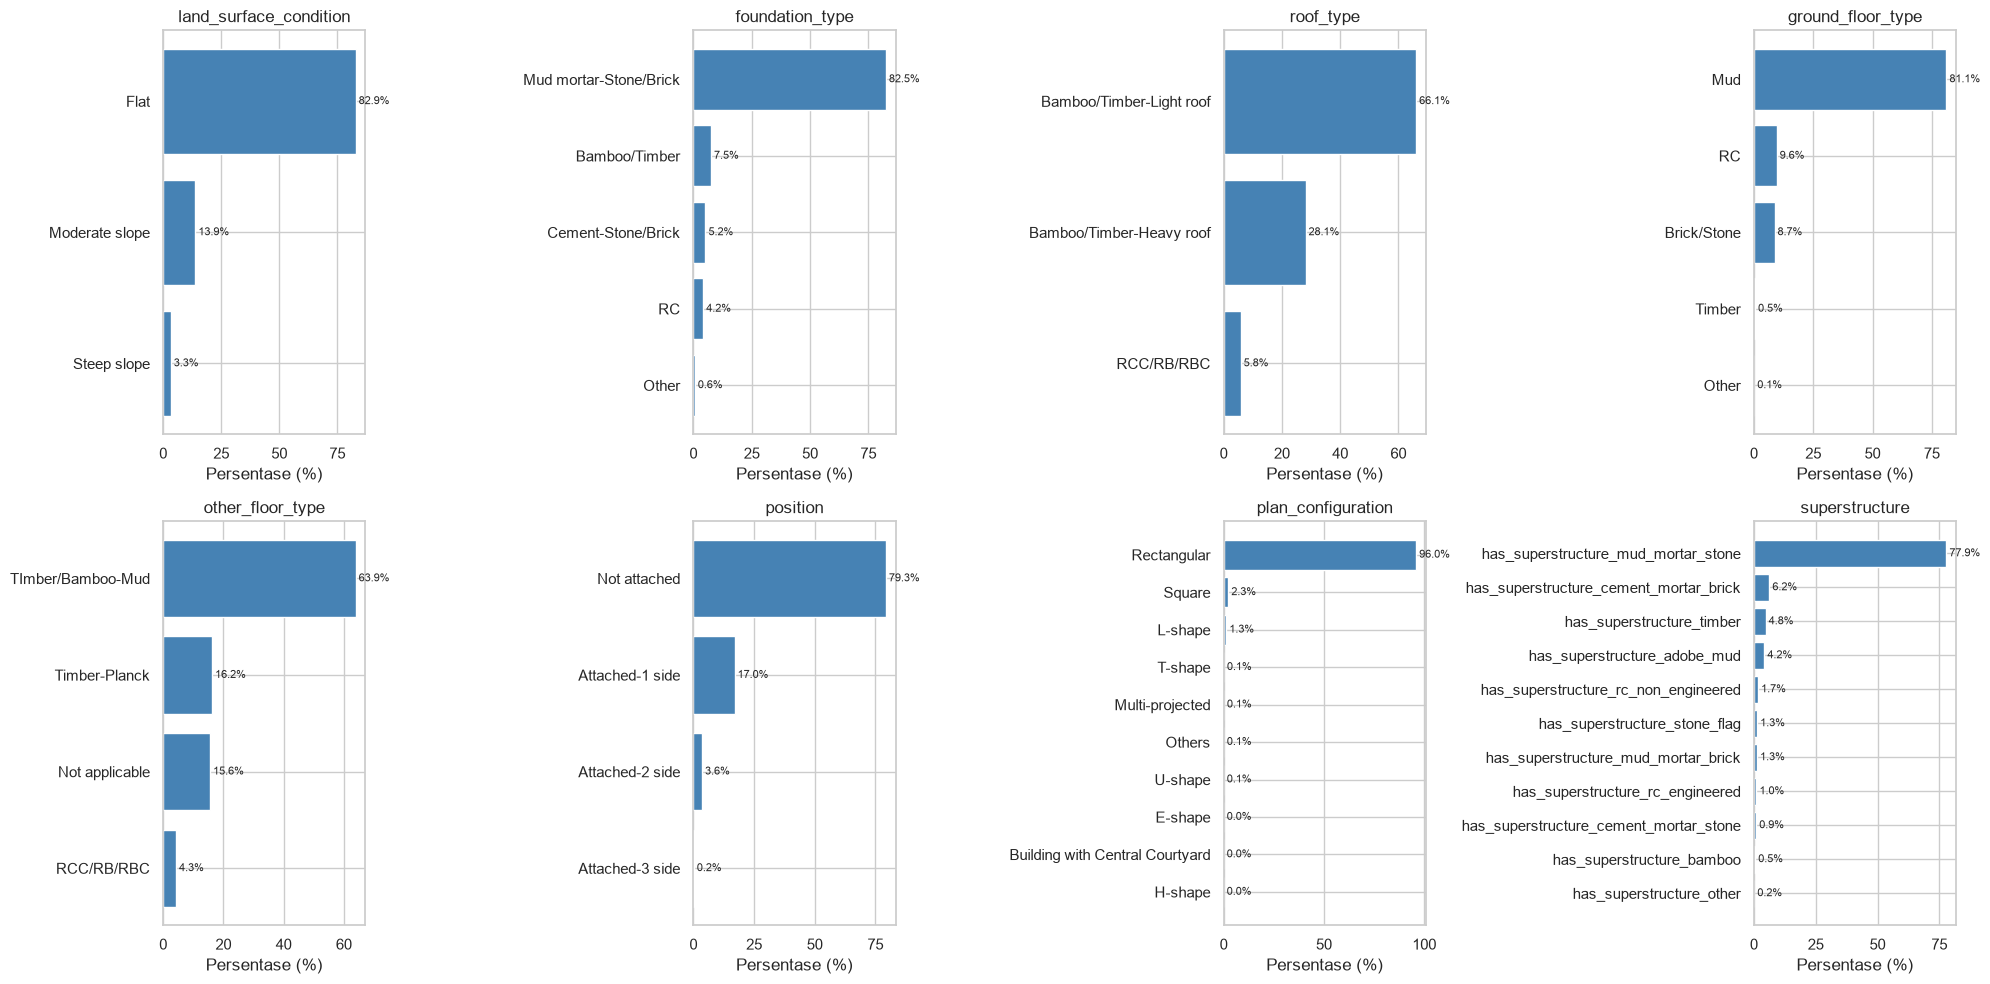

In [30]:
## 6. Univariat Kategorik
# Proporsi kategori tiap kolom kategorik
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for ax, col in zip(axes.flat, CAT_COLS):
    prop = train[col].value_counts(normalize=True).mul(100).sort_values()
    ax.barh(prop.index, prop.values, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("Persentase (%)")
    for i, v in enumerate(prop.values):
        ax.text(v, i, f" {v:.1f}%", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("../reports/figures/univariat_kategorik.png", dpi=150)
plt.show()

**Insight univariat kategorik:**
- Seluruh kolom kategorik didominasi satu kategori (>60%), umumnya konstruksi tradisional: fondasi mud mortar-stone/brick (82,5%), lantai dasar mud (81,1%), superstructure mud mortar-stone (77,9%).
- Konstruksi modern (RC/RCC) hanya sekitar 4–10% pada tiap kolom.
- Beberapa kolom diduga saling berkaitan (misalnya fondasi RC dengan lantai RC) dan akan diperiksa pada analisis multivariat.

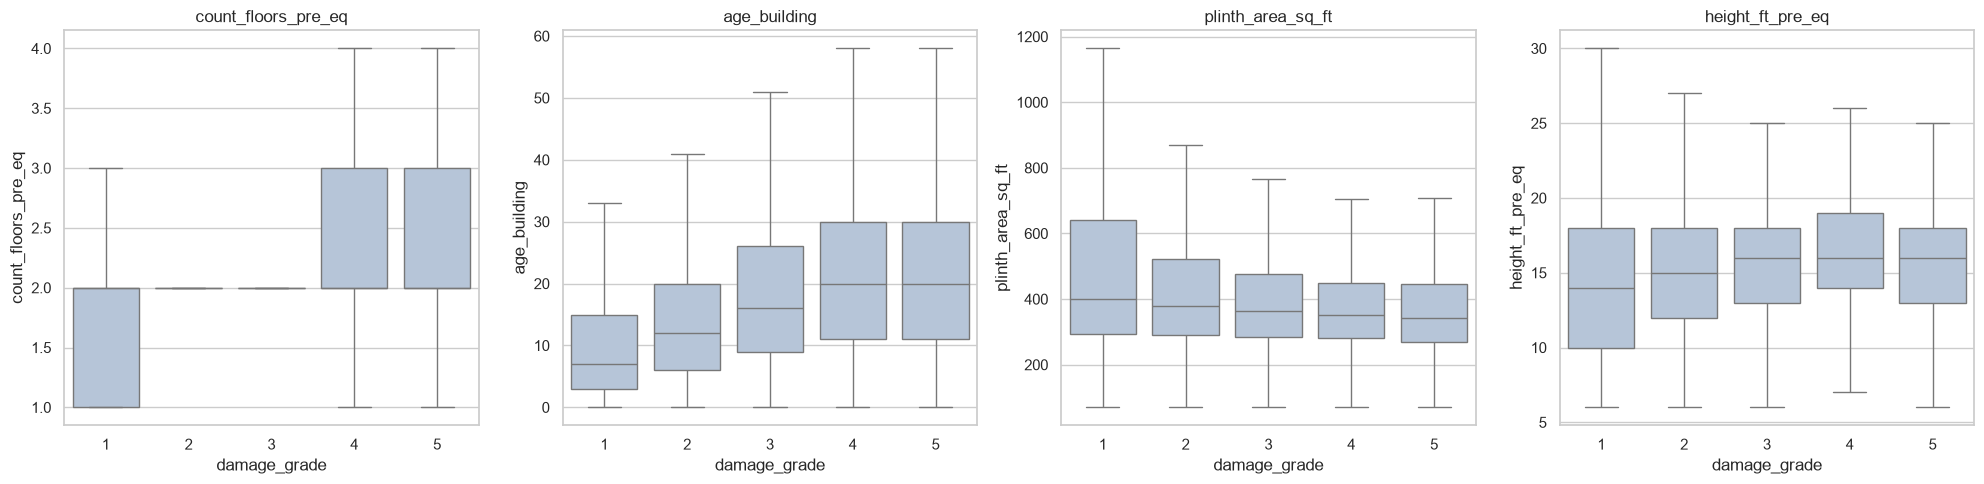

In [31]:
## 7. Bivariat (Fitur vs Target)
### 7.1 Numerik vs Target
# Sebaran fitur numerik pada tiap damage grade (outlier tidak ditampilkan)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=eda, x="damage_grade", y=col, ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_title(col)

plt.tight_layout()
plt.savefig("../reports/figures/bivariat_numerik.png", dpi=150)
plt.show()

In [32]:
# Median tiap fitur numerik per grade
display(eda.groupby("damage_grade")[NUM_COLS].median())

# Uji Kruskal-Wallis: apakah sebaran fitur berbeda antar grade
for col in NUM_COLS:
    grup = [g[col].dropna() for _, g in eda.groupby("damage_grade")]
    h, p = stats.kruskal(*grup)
    print(f"{col}: H = {h:,.0f} | p-value = {p:.2e}")

,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq
damage_grade,,,,
1,2.000,7.000,400.000,14.000
2,2.000,12.000,380.000,15.000
3,2.000,16.000,364.000,16.000
4,2.000,20.000,350.000,16.000
5,2.000,20.000,342.000,16.000


count_floors_pre_eq: H = 27,741 | p-value = 0.00e+00
age_building: H = 48,976 | p-value = 0.00e+00
plinth_area_sq_ft: H = 8,005 | p-value = 0.00e+00
height_ft_pre_eq: H = 8,525 | p-value = 0.00e+00


**Insight bivariat numerik:**
- Seluruh fitur numerik berbeda signifikan antar grade (Kruskal-Wallis, p < 0,05); perbandingan kekuatan menggunakan statistik H.
- `age_building` merupakan fitur numerik terkuat (H = 48.976): median umur meningkat dari 7 tahun (Grade 1) hingga 20 tahun (Grade 4–5).
- `count_floors_pre_eq` (H = 27.741): Grade 1 didominasi bangunan 1–2 lantai, sedangkan Grade 4–5 lebih banyak bangunan 3 lantai.
- `plinth_area_sq_ft` berhubungan negatif dengan kerusakan (median 400 → 342 sq ft), sedangkan `height_ft_pre_eq` berhubungan positif lemah.
- Grade 4 dan 5 hampir tidak dapat dibedakan melalui fitur numerik, sehingga diduga sering tertukar saat prediksi.
- Kandidat fitur baru: `height_per_floor` dan `total_area` (plinth × jumlah lantai).

In [33]:
### 7.2 Kategorik vs Target
# Fungsi Cramér's V untuk mengukur kekuatan hubungan dua variabel kategorik
def cramers_v(x, y):
    """Menghitung Cramér's V (0 = tidak berhubungan, 1 = berhubungan sempurna)."""
    tabel = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabel)[0]
    n = tabel.values.sum()
    return np.sqrt(chi2 / (n * (min(tabel.shape) - 1)))

# Ranking fitur kategorik dan geografis terhadap target
kolom_uji = CAT_COLS + GEO_COLS + ["count_floors_pre_eq"]
hasil = pd.DataFrame({
    "cramers_v": [cramers_v(train[c], train["damage_grade"]) for c in kolom_uji],
    "n_kategori": [train[c].nunique() for c in kolom_uji]
}, index=kolom_uji).sort_values("cramers_v", ascending=False)

hasil

,cramers_v,n_kategori
ward_id,0.449,945
vdcmun_id,0.370,110
district_id,0.301,11
superstructure,0.300,11
roof_type,0.287,3
foundation_type,0.256,5
other_floor_type,0.250,4
ground_floor_type,0.225,5
count_floors_pre_eq,0.156,9
plan_configuration,0.054,10


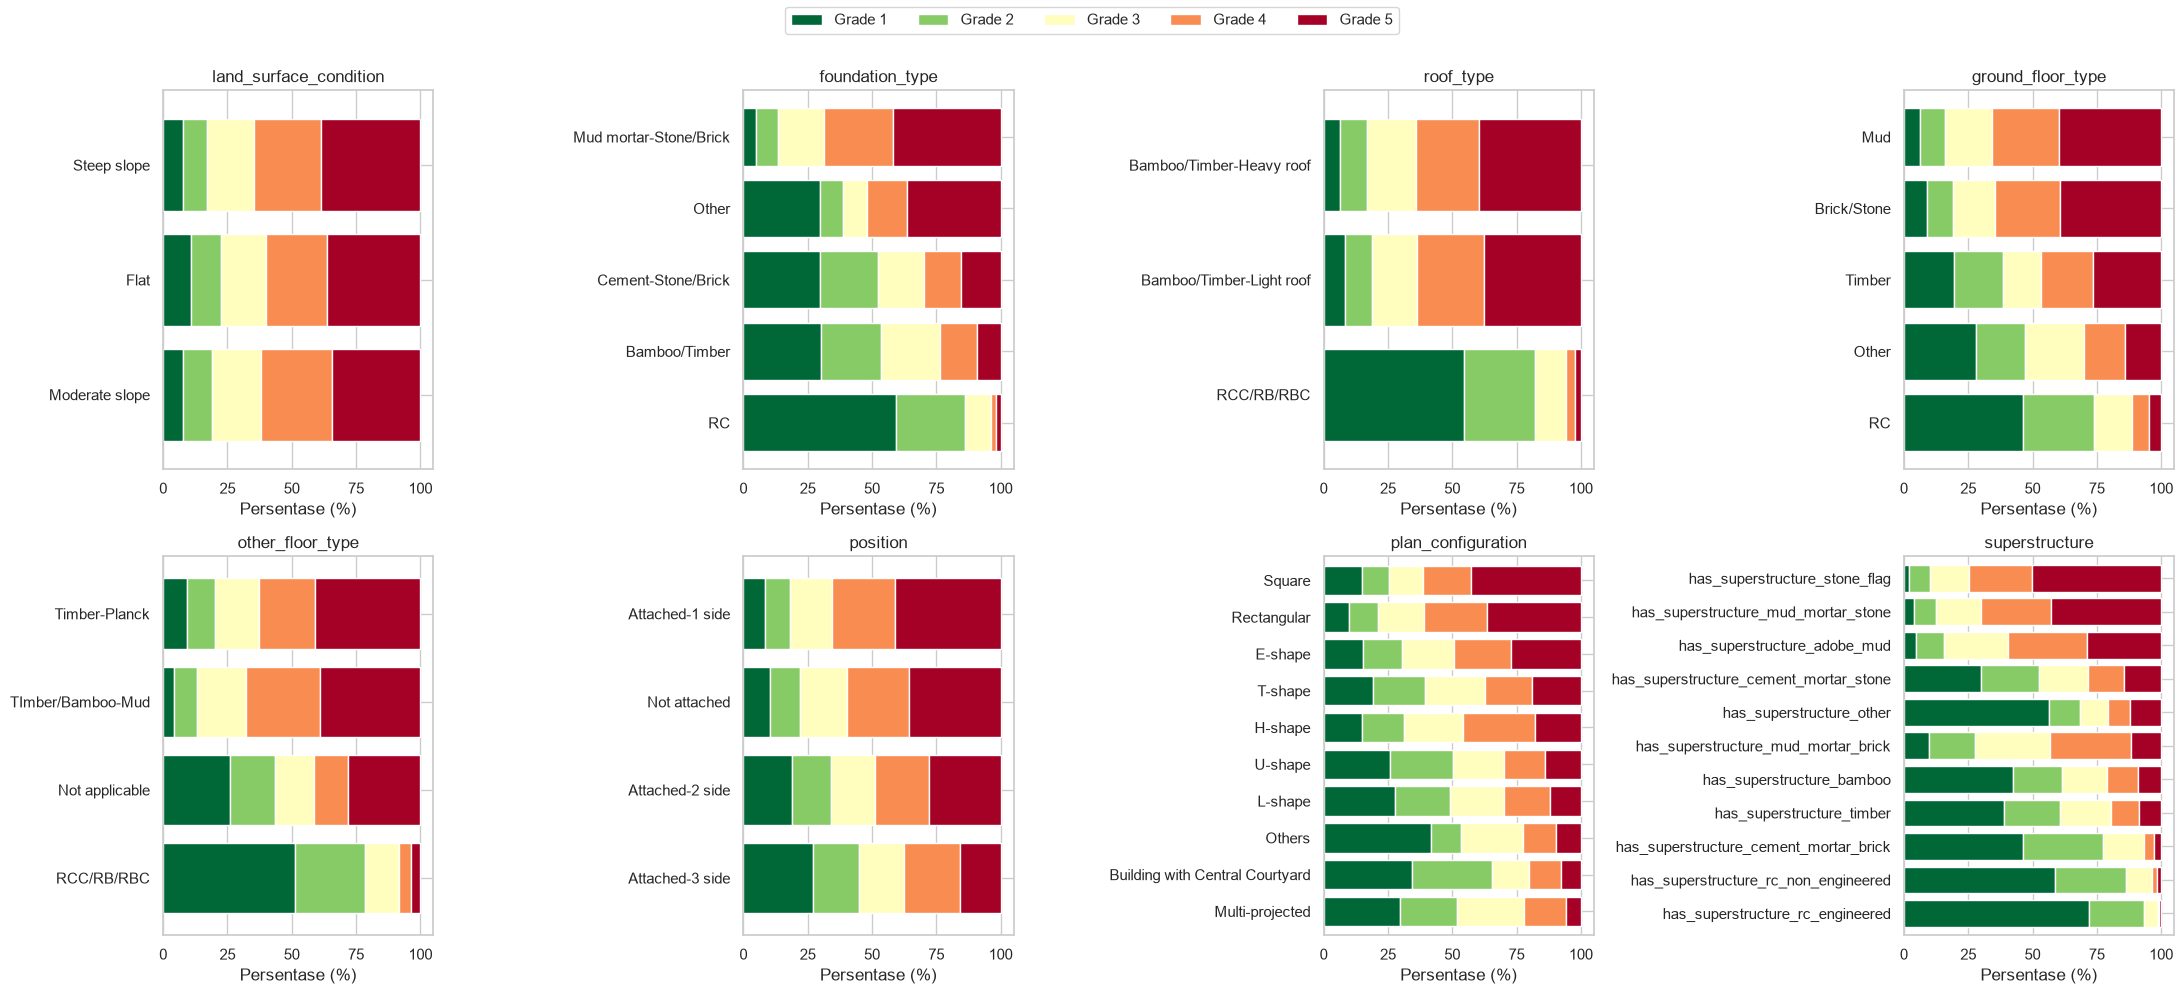

In [34]:
# Komposisi damage grade (%) pada tiap kategori
fig, axes = plt.subplots(2, 4, figsize=(22, 10))

for ax, col in zip(axes.flat, CAT_COLS):
    ct = pd.crosstab(train[col], train["damage_grade"], normalize="index").mul(100)
    ct = ct.sort_values(5)
    ct.plot(kind="barh", stacked=True, ax=ax, colormap="RdYlGn_r", legend=False, width=0.8)
    ax.set_title(col)
    ax.set_xlabel("Persentase (%)")
    ax.set_ylabel("")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, [f"Grade {l}" for l in labels], loc="upper center", ncol=5)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("../reports/figures/bivariat_kategorik.png", dpi=150)
plt.show()


**Insight bivariat kategorik:**
- Lokasi merupakan faktor terkuat: `ward_id` (V = 0,45), `vdcmun_id` (0,37), dan `district_id` (0,30). Nilai pada `ward_id` berpotensi sedikit terinflasi akibat jumlah kategori yang besar (945).
- Material konstruksi berhubungan sedang–kuat (V = 0,22–0,30). Kategori modern (RC/RCC, rc_engineered) didominasi Grade 1–2, sedangkan material tradisional (mud mortar-stone, stone flag) didominasi Grade 4–5.
- Bangunan 1 lantai ("Not applicable") cenderung mengalami kerusakan lebih ringan.
- `plan_configuration`, `position`, dan `land_surface_condition` berhubungan lemah (V < 0,06), namun tetap dipertahankan untuk diuji pada tahap modeling.
- Proporsi Grade 4 dan 5 serupa pada kategori tradisional, menguatkan dugaan kedua kelas sulit dipisahkan.

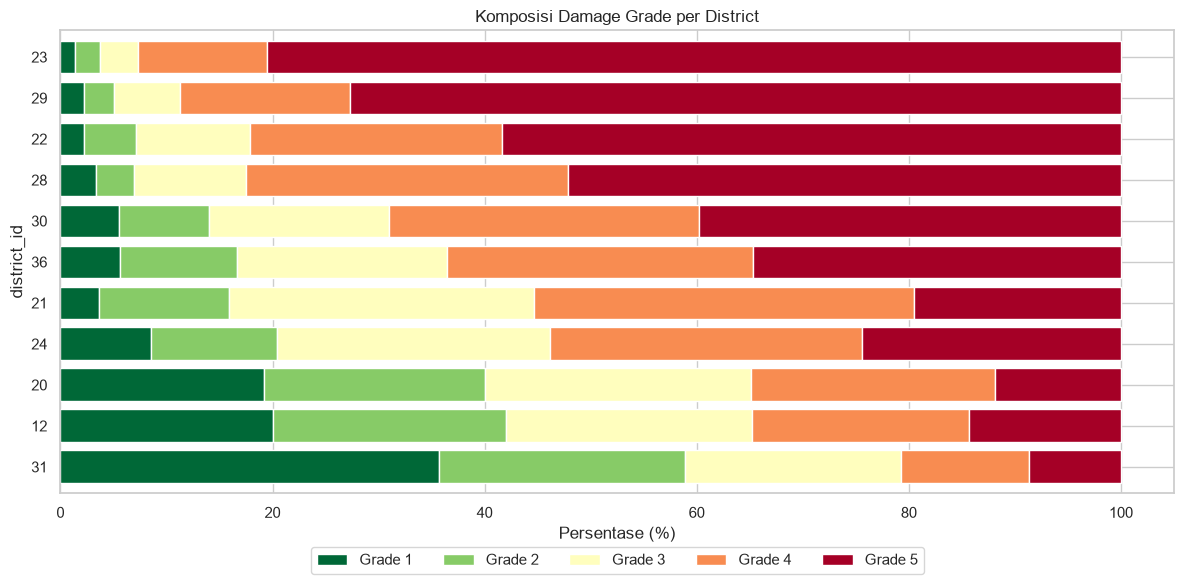

damage_grade,rata_grade,jumlah
district_id,,
31,2.350,63557
12,2.870,27651
20,2.880,48133
24,3.490,68616
21,3.550,41095
36,3.760,54751
30,3.890,62461
28,4.240,53704
22,4.310,42465


In [35]:
### 7.3 Lokasi vs Target
# Komposisi damage grade per district, diurutkan berdasarkan rata-rata grade
ct = pd.crosstab(train["district_id"], train["damage_grade"], normalize="index").mul(100)
ct["rata_grade"] = train.groupby("district_id")["damage_grade"].mean()
ct["jumlah"] = train["district_id"].value_counts()
ct = ct.sort_values("rata_grade")

ax = ct[[1, 2, 3, 4, 5]].plot(kind="barh", stacked=True, figsize=(12, 6), colormap="RdYlGn_r", width=0.8)
ax.set_title("Komposisi Damage Grade per District")
ax.set_xlabel("Persentase (%)")
ax.legend([f"Grade {i}" for i in range(1, 6)], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5)
plt.tight_layout()
plt.savefig("../reports/figures/bivariat_district.png", dpi=150)
plt.show()

ct[["rata_grade", "jumlah"]].round(2)

In [36]:
# Variasi rata-rata grade antar municipality di dalam tiap district
var_vdc = (train.groupby(["district_id", "vdcmun_id"])["damage_grade"].mean()
           .groupby("district_id").agg(["min", "max", "std"]).round(2))
var_vdc

,min,max,std
district_id,,,
12,2.130,3.770,0.620
20,2.210,3.720,0.430
21,3.290,4.090,0.300
22,3.730,4.830,0.380
23,4.150,4.870,0.200
24,2.950,4.280,0.380
28,3.940,4.750,0.260
29,4.100,4.770,0.300
30,3.130,4.800,0.500


**Insight lokasi:**
- Rata-rata grade per district berkisar dari 2,35 (district 31) hingga 4,68 (district 23); lebih dari 80% bangunan di district 23 mengalami Grade 5.
- District dapat dikelompokkan menjadi wilayah terdampak parah (28, 22, 29, 23), sedang (24, 21, 36, 30), dan ringan (31, 12, 20), diduga terkait jarak terhadap episentrum.
- Variasi antar municipality di dalam district masih besar (contoh district 12: rata-rata 2,13–3,77), sehingga `vdcmun_id` dan `ward_id` memberikan informasi tambahan di luar `district_id`.
- Ketiga kolom lokasi dipertahankan dengan rencana encoding: OneHotEncoder untuk `district_id` dan TargetEncoder untuk `vdcmun_id` serta `ward_id`.

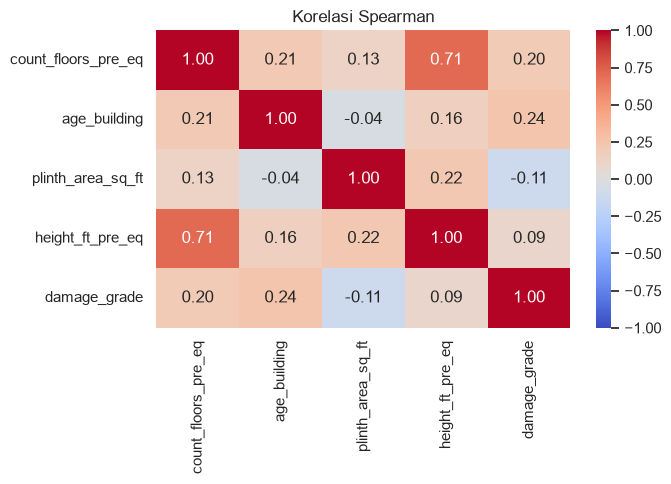

In [37]:
## 8. Multivariat
### 8.1 Korelasi antar Fitur Numerik
# Korelasi Spearman antar fitur numerik dan target
korelasi = eda[NUM_COLS + ["damage_grade"]].corr(method="spearman")

plt.figure(figsize=(7, 5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi Spearman")
plt.tight_layout()
plt.savefig("../reports/figures/korelasi_numerik.png", dpi=150)
plt.show()

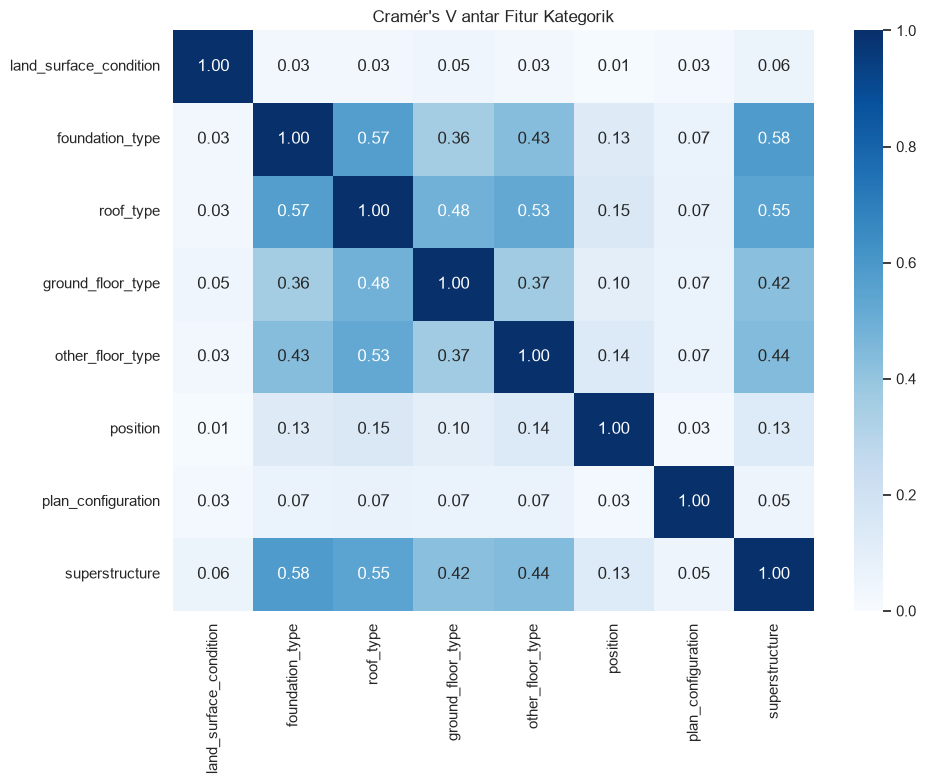

In [38]:
### 8.2 Asosiasi antar Fitur Kategorik
# Matriks Cramér's V antar fitur kategorik
cv_matrix = pd.DataFrame(index=CAT_COLS, columns=CAT_COLS, dtype=float)
for a in CAT_COLS:
    for b in CAT_COLS:
        cv_matrix.loc[a, b] = 1.0 if a == b else cramers_v(train[a], train[b])

plt.figure(figsize=(10, 8))
sns.heatmap(cv_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V antar Fitur Kategorik")
plt.tight_layout()
plt.savefig("../reports/figures/cramers_kategorik.png", dpi=150)
plt.show()


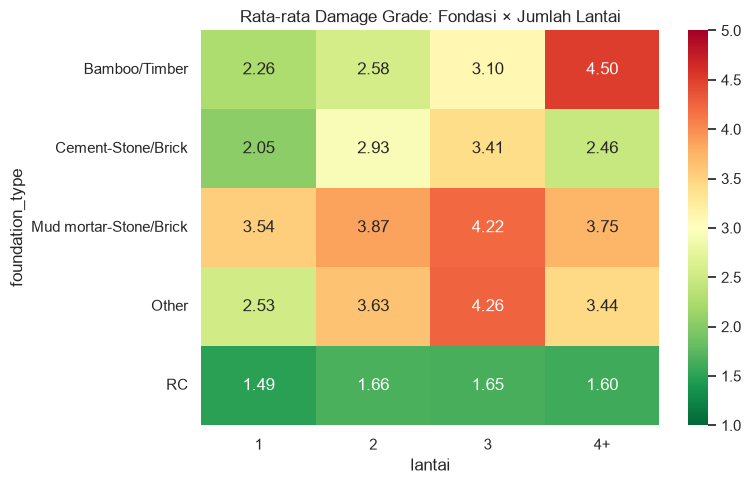

In [39]:
### 8.3 Interaksi Fitur
# Rata-rata damage grade berdasarkan kombinasi fondasi dan jumlah lantai
lantai = eda["count_floors_pre_eq"].clip(upper=4).astype(str).replace("4", "4+")
pivot = eda.assign(lantai=lantai).pivot_table(
    index="foundation_type", columns="lantai", values="damage_grade", aggfunc="mean")

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn_r", vmin=1, vmax=5)
plt.title("Rata-rata Damage Grade: Fondasi × Jumlah Lantai")
plt.tight_layout()
plt.savefig("../reports/figures/interaksi_fondasi_lantai.png", dpi=150)
plt.show()

In [40]:
# Korelasi Spearman kandidat fitur baru terhadap target
rc_cols = ["foundation_type", "roof_type", "ground_floor_type", "other_floor_type"]
cek = pd.DataFrame({
    "height_per_floor": eda["height_ft_pre_eq"] / eda["count_floors_pre_eq"],
    "total_area": eda["plinth_area_sq_ft"] * eda["count_floors_pre_eq"],
    "rc_count": sum(eda[c].str.contains("RC") for c in rc_cols) + eda["superstructure"].str.contains("rc_").astype(int),
    "damage_grade": eda["damage_grade"]
})
cek.corr(method="spearman")["damage_grade"].round(3)

height_per_floor   -0.183
total_area          0.024
rc_count           -0.379
damage_grade        1.000
Name: damage_grade, dtype: float64

**Insight interaksi dan kandidat fitur:**
- Terdapat interaksi antara jenis fondasi dan jumlah lantai: pada fondasi RC rata-rata grade stabil (1,5–1,7) di semua jumlah lantai, sedangkan pada fondasi Bamboo/Timber meningkat tajam dari 2,26 (1 lantai) menjadi 4,50 (4+ lantai).
- Pola interaksi dan non-linear ini mengindikasikan model berbasis pohon lebih sesuai dibanding model linear.
- `rc_count` (Spearman -0,379) lebih kuat dibanding seluruh fitur numerik asli, dan `height_per_floor` (-0,183) lebih kuat dibanding `height_ft_pre_eq` (0,09); keduanya akan dibuat pada tahap feature engineering.
- `total_area` (0,024) tidak memberikan informasi tambahan sehingga tidak digunakan.

In [41]:
## 9. Perbandingan Train vs Test
# Statistik fitur numerik pada train dan test
banding_num = pd.concat({
    "train_mean": train[NUM_COLS].mean(),
    "test_mean": test[NUM_COLS].mean(),
    "train_median": train[NUM_COLS].median(),
    "test_median": test[NUM_COLS].median()
}, axis=1).round(2)
banding_num

,train_mean,test_mean,train_median,test_median
count_floors_pre_eq,2.090,2.090,2.000,2.000
age_building,24.340,24.300,16.000,16.000
plinth_area_sq_ft,406.520,407.020,358.000,360.000
height_ft_pre_eq,16.050,16.050,16.000,16.000


In [42]:
# Selisih proporsi kategori terbesar antara train dan test (dalam poin persen)
selisih = {}
for col in CAT_COLS + GEO_COLS:
    p_train = train[col].value_counts(normalize=True)
    p_test = test[col].value_counts(normalize=True)
    selisih[col] = (p_train - p_test).abs().max() * 100

pd.Series(selisih, name="selisih_maks_%").sort_values(ascending=False).round(3)

district_id              0.187
roof_type                0.121
plan_configuration       0.080
vdcmun_id                0.076
position                 0.068
other_floor_type         0.063
superstructure           0.057
foundation_type          0.057
land_surface_condition   0.049
ground_floor_type        0.039
ward_id                  0.029
Name: selisih_maks_%, dtype: float64

**Insight train vs test:**
- Statistik fitur numerik pada train dan test hampir identik (contoh median `age_building` 16 pada keduanya).
- Selisih proporsi kategori terbesar hanya 0,187 poin persen (`district_id`), mengindikasikan pembagian train–test dilakukan secara acak tanpa distribution shift.
- Skor cross-validation pada train dapat digunakan sebagai estimasi yang andal untuk skor leaderboard, sehingga pemilihan model didasarkan pada skor CV.

## 10. Pengecekan Leakage

| Sumber potensi leakage | Status | Penanganan |
|---|---|---|
| Fitur berisi informasi pasca-gempa | Tidak ditemukan; seluruh fitur menggambarkan kondisi sebelum gempa (`_pre_eq`) | – |
| `building_id` sebagai fitur | Berisiko karena hanya identitas | Dikeluarkan dari fitur, hanya digunakan untuk submission |
| Bangunan yang sama pada train dan test | Tidak ada irisan `building_id` | – |
| Target encoding pada `vdcmun_id` dan `ward_id` | Berisiko jika dihitung dari seluruh train | TargetEncoder dengan cross-fitting di dalam pipeline |
| Imputasi dan scaling | Berisiko jika di-fit pada seluruh data | Seluruh transformasi di-fit di dalam pipeline pada data latih setiap fold |

## 11. Kesimpulan EDA dan Keputusan Preprocessing

**Temuan utama:**
1. Data terdiri dari 533.465 bangunan (train) dan 228.629 bangunan (test) tanpa missing value eksplisit.
2. Target imbalanced sedang (Grade 5: 36,2%, Grade 1: 10,3%; rasio 3,5).
3. Lokasi merupakan faktor terkuat (Cramér's V `ward_id` 0,45; rata-rata grade per district 2,35–4,68).
4. Material konstruksi berhubungan sedang–kuat; konstruksi RC didominasi Grade 1–2, material tradisional didominasi Grade 4–5.
5. Umur bangunan merupakan fitur numerik terkuat; fitur numerik lain berhubungan lemah dengan target.
6. Terdapat interaksi fondasi × jumlah lantai sehingga model berbasis pohon diperkirakan lebih unggul.
7. Grade 4 dan 5 memiliki karakteristik serupa dan diperkirakan sering tertukar.
8. Distribusi train dan test identik sehingga skor CV dapat dipercaya.

**Keputusan preprocessing:**

| Kolom | Penanganan |
|---|---|
| `building_id` | Dikeluarkan dari fitur |
| `damage_grade` | Konversi "Grade X" → X (1–5) |
| `age_building` | 999 → NaN, imputasi median, `log1p` (model linear) |
| `height_ft_pre_eq` | 99 → NaN, imputasi median |
| `plinth_area_sq_ft` | `log1p` (model linear) |
| Numerik | StandardScaler (model linear) |
| 8 kolom kategorik | OneHotEncoder (`handle_unknown="ignore"`, `min_frequency`) |
| `district_id` | OneHotEncoder |
| `vdcmun_id`, `ward_id` | TargetEncoder (cross-fitting) |
| Fitur baru | `rc_count`, `height_per_floor` |
| Outlier & duplikat | Dipertahankan |

**Strategi modeling:**
- Validasi: StratifiedKFold dengan metrik Macro F1.
- Imbalance: `class_weight="balanced"` dan/atau penyesuaian threshold.
- Kandidat model: Logistic Regression (baseline, OvR vs OvO), Random Forest, LightGBM/XGBoost.